---
### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling


------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


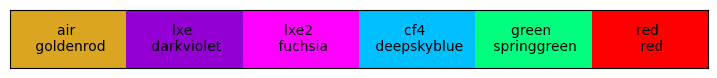

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False, dh = None):
    # to use later
    if smoothSigma is not None:
        theseArgsDict = locals()
        del theseArgsDict["wlen"]
        theseArgsDict["smoothSigma"] = None

    photon = PhotonInfo(wlen, theta1, dataHelper=dh)    
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        NperSigma = 5
        stepSize = smoothSigma / NperSigma
        NsigmaPast = 3
        newXVals = np.arange(min(wlen)-NsigmaPast*smoothSigma, max(wlen) + NsigmaPast*smoothSigma + stepSize, stepSize) # for full array at once. requires interp1d below
        fullerPDEVals = PDE_allArgs(wlen=newXVals, **theseArgsDict) # WASN'T RECURSIVELY PASSING dh BEFORE
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=NperSigma) # this sigma argument is saying 'how many X points correspond to 1sigma'
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)     
        
    return PDE

In [3]:
someXs = np.arange(300, 1000, 10)
start = time.time()

i=0
while i < 500:
    yPDE_P = PDE_allArgs(wlen=someXs, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=10, quantum = False)
    i+=1

end_time = time.time()
print("Time to run: ", end_time - start)

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
Time to run:  0.6758899688720703


-----------------------------
Silicon data from
   ../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-------------------------- xx ------------
/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-------

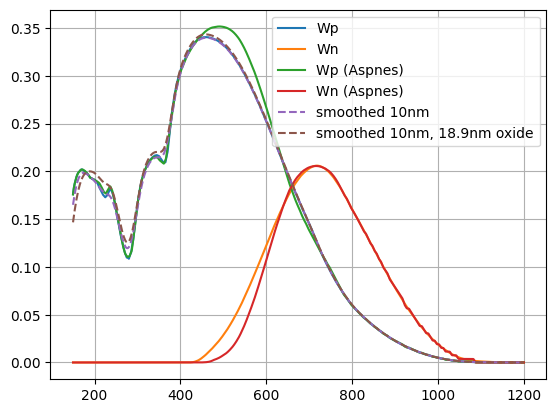

In [4]:
# plotting PDE if probabilities were 1 (for Wp, Wn)
dhStandard = OpticsData()
dhAspnes = OpticsData(siDataPath="../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt")

print("-------------------------- xx ------------")
print(dhStandard.mPathSi)
print(dhAspnes.mPathSi)

xVals = np.arange(150, 1200, 1)
yPDE_P = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=None, quantum = False)
yPDE_N = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=0, ph=1, smoothSigma=None, quantum = False)

yPDE_P_aspnes = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=None, quantum = False, dh=dhAspnes)
yPDE_N_aspnes = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=0, ph=1, smoothSigma=None, quantum = False, dh=dhAspnes)

yPDE_P_aspnes_smooth = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=10, quantum = False)

yPDE_P_aspnes_smooth_Thicker = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=18.9, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=10, quantum = False)


plt.plot(xVals, yPDE_P, label='Wp')
plt.plot(xVals, yPDE_N, label='Wn')

plt.plot(xVals, yPDE_P_aspnes, label='Wp (Aspnes)')
plt.plot(xVals, yPDE_N_aspnes, label='Wn (Aspnes)')

plt.plot(xVals, yPDE_P_aspnes_smooth, linestyle="--", label='smoothed 10nm')

plt.plot(xVals, yPDE_P_aspnes_smooth_Thicker, linestyle="--", label='smoothed 10nm, 18.9nm oxide')

# plt.xlim(200, 450)
plt.legend()
plt.grid()
plt.show()

---
### Loading Data

In [5]:
file_path = os.path.join(PROPATH, "../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv")
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


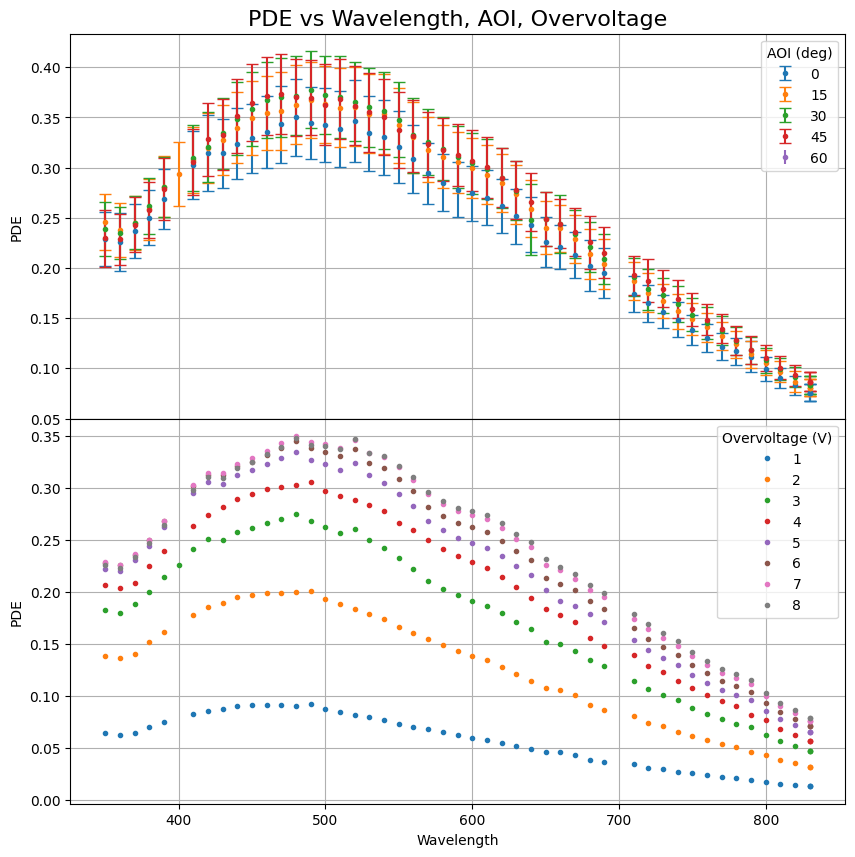

Angles: [0 1 2 3 4 5 6 7 8]
voltages: [0 1 2 3 4 5 6 7 8]


In [6]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 7)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

    Wavelength  Overvoltage  Raw rate     Error  normalized rate
45         380            1   85685.2  4284.260         0.486306
46         380            2  129270.0   102.441         0.733673
47         380            3  151277.0   112.130         0.858569
48         380            4  163067.0   117.333         0.925484
49         380            5  169473.0   120.277         0.961845
50         380            6  172971.0   121.836         0.981696
51         380            7  174974.0   122.416         0.993065
52         380            8  175686.0   122.464         0.997103
53         380            9  176196.0  8809.810         1.000000
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


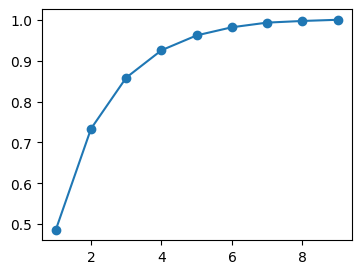

In [7]:
## Loading in Harry's PE data
file_path_pe = os.path.join(PROPATH, "../veraData/HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 3))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

---
---
## Parameters shared by everything

In [8]:
FF1 = 0.6
scaleErrors = 0.3
# scaleHarry = 0
fixedPars_Boring = {"FF": FF1, "quantum": False, "smoothSigma": None, "dh":dhAspnes}

ttGood = 16.5 # good thickness in nm

---
---
### UV high V Dataset
No nested/nuisance pars are required here  


In [9]:
##-- Buiding A1 dataset --##
UVLim = 450
# dataset 0A
v_0A = data_voltages[-1]
v_0A2 = data_voltages[-2]
angle_0A = data_angles[0]

# temporary datasets
dfA_t1 = df[(df['Overvoltage'] == v_0A) & (df['Angle'] == angle_0A) & (df['Wavelength'] < UVLim)]
dfA2_t2 = df[(df['Overvoltage'] == v_0A2) & (df['Angle'] == angle_0A)& (df['Wavelength'] < UVLim)]
data_UV_V = [
    # {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A},
    {"wlen":dfA2_t2['Wavelength'], "yVals": dfA2_t2['PDE'], "yErrs": dfA2_t2['PDE_error']*scaleErrors, "theta1": angle_0A}
    ]

print("voltage wanted:", v_0A2, "V")
print("angle wanted:", angle_0A, "deg")
# print("data_UV_V[0]:", data_UV_V[0])

SS.CheckDataSetKey_consistent(data_UV_V, True);

voltage wanted: 7 V
angle wanted: 0 deg
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


---
---
### UV high V Fitting: Permutation A
No nested/nuisance pars are required here  
Global float: 
* float $P_e$, $dp^*$
* $t_{oxide} = 16.5$ nm

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 1.9377983014285232
{'dp_star': 1.2213, 'pe': 0.9443}
errors: {'dp_star': 0.2039, 'pe': 0.0096}


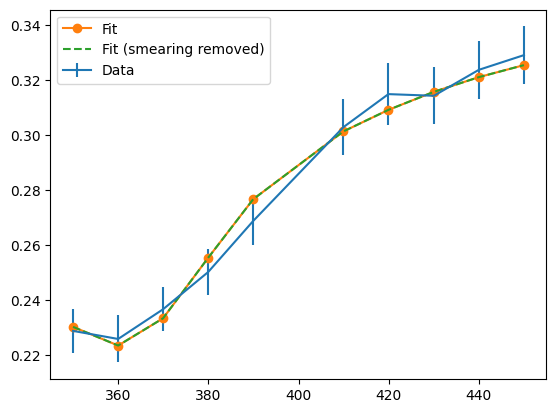

In [10]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_A_UV = {"tOxide": ttGood, "Xpn": 1.8e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_A_UV = { "dp_star": 5, "pe": 0.98}
floatBounds_A_UV = {"dp_star": (0.5, 14), "pe": (0.7, 1.1)}
# SS.AddNonesToDict(dAddTo=floatBounds_A_UV, dRef=floatPars_A_UV)

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)


resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_A_UV, **fixedPars_A_UV)

# plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit", marker="o")

toPlotNarrow = fixedPars_A_UV.copy()
toPlotNarrow['smoothSigma'] = None
yTestNarrow=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **toPlotNarrow)
plt.plot(data_UV_V[0]["wlen"], yTestNarrow, label="Fit (smearing removed)", linestyle="--")

plt.legend()
plt.show()

---
### UV high V Fitting: Permutation B
No nested/nuisance pars are required here  
* float: $dp^*$
* $P_e = 1.0$, $t_{oxide}=16.5$ nm

In [11]:
# # global fixed
# print("List of args needed:", SS.GetNames(PDE_allArgs))

# fixedPars_B_UV = {"tOxide": ttGood, "pe": 1.0, "Xpn": 2e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

# floatPars_B_UV = { "dp_star": 1.5}
# floatBounds_B_UV = {"dp_star": (0.5, 14)}
# # SS.AddNonesToDict(dAddTo=floatBounds_B_UV, dRef=floatPars_B_UV)

# print("------ Case AE-UV setup ------")
# SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_B_UV, dFloat=floatPars_B_UV,
#                                    dBounds=floatBounds_B_UV, yNames=("yVals", "yErrs"), verbose=False)
# xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_B_UV, functionToFit=PDE_allArgs)
# xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_B_UV, functionToFit=PDE_allArgs)

# print("------ Case B-UV Fit ------")
# result_B_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_B_UV, data_UV_V, PDE_allArgs), method='migrad')
# SS.GenericResiduals(x0=result_B_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_B_UV, verbose=False, yNames=("yVals", "yErrs"))
# # print(result_B_UV)
# print("chi2 score-ish:", result_B_UV.fun)

# resDict_B_UV = SS.GetResDict(result_B_UV, xoAE_UV_Names)
# resDictErrors_B_UV = SS.GetResErrorDict(result_B_UV, xoAE_UV_Names)
# print(resDict_B_UV)
# print("errors:", resDictErrors_B_UV)

# ## plotting ##
# # plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
# yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_B_UV, **fixedPars_B_UV)
# plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
# plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

# yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_B_UV, **fixedPars_B_UV)
# plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit")

# ax = plt.gca()
# ax.set_facecolor((1, 0, 0, 0.2))
# plt.legend()
# plt.show()

---
---
### UV - __all V__ Datasets
Now $P_e$ is a nuisance parameter (float or fixed)
* __A__: float nested: $P_e$
* __C__: fix $P_e$ to Harry's values
* __E__: float global: $t_{oxide}$ ??

Will attempt A, C, EC


In [12]:
##-- Buiding A1 dataset --##
# dataset 0A
angle_0A = data_angles[0]
print("data voltages:", data_voltages)

data_UV_all = []
voltageTracker = []
for V in data_voltages[1:-1]:
    voltageTracker.append(V)
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < UVLim)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    data_UV_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(data_UV_all, True);
print("voltages used:", voltageTracker)

data voltages: [0 1 2 3 4 5 6 7 8]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
voltages used: [1, 2, 3, 4, 5, 6, 7]


In [13]:
## Building different Nuisance Parameter datasets
data_UVall_A = [] # float Pe
data_UVall_C = [] # use Harry's fixed Pe

for V, oneD in zip(voltageTracker, data_UV_all):
    
    nuisFixed_C = {"pe": harryPedict[V]}
    print("V:", V, "guess pe:", harryPedict[V])
    
    nuisFloat_A = {"pe": harryPedict[V]}
    nuiseFloatBounds_A = {"pe": (0.0, 1.1)}
    
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat=nuisFloat_A, nuisanceBounds=nuiseFloatBounds_A, nuisanceFixed={})
    odFullA.extraV = V
    
    odFullC = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat={}, nuisanceBounds={}, nuisanceFixed=nuisFixed_C)
    odFullC.extraV = V
    
    data_UVall_A.append(odFullA)
    data_UVall_C.append(odFullC)

V: 1 guess pe: 0.486306
V: 2 guess pe: 0.733673
V: 3 guess pe: 0.858569
V: 4 guess pe: 0.925484
V: 5 guess pe: 0.961845
V: 6 guess pe: 0.981696
V: 7 guess pe: 0.993065


---
### UV All V Fitting: Permutation A (nested Pe float)

* global float: $dp^*$
* local float: $P_e$
* fixed: $t_{oxide}$

In [14]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global_A = {"tOxide":ttGood,"Xpn": 1.5e3, "dw_star":10e3, "ph":0., **fixedPars_Boring}

floatPars_global_A = { "dp_star": 5}
floatBounds_A_UV = {"dp_star": (0.5, 15)}

x0_global_A, x0_global_A_Names = SS.BuildX0(floatDict=floatPars_global_A, functionToFit=PDE_allArgs)
x0_global_A_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case A-UVall setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_A, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
------ Case A-UVall setup ------


1376.662296174413

In [15]:
globalFit_UVall_A = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_A, bounds = x0_global_A_bounds,
                                     args=(fixedPars_global_A, data_UVall_A, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_UVall_A.x, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)
print("done fit")

done fit


In [16]:
# print(globalFit_UVall_A)
resDict_A_UVall = SS.GetResDict(globalFit_UVall_A, x0_global_A_Names)
resErrors_A_UVall = SS.GetResErrorDict(globalFit_UVall_A, x0_global_A_Names)


print("------ Case A-UVall Fit ------")

print("chi2 score-ish:", globalFit_UVall_A.fun)
print(resDict_A_UVall)
print(resErrors_A_UVall)

peVals_A = [dc.resultDict["pe"] for dc in data_UVall_A]
peVals_A_dict = {dc.extraV: dc.resultDict["pe"] for dc in data_UVall_A}
peErrs_A_dict = {dc.extraV: dc.resultErrorsDict["pe"] for dc in data_UVall_A}
print("peVals_A_dict:", peVals_A_dict)
print("peErrs_A_dict:", peErrs_A_dict)

------ Case A-UVall Fit ------
chi2 score-ish: 15.882982350894522
{'dp_star': 1.1625}
{'dp_star': 0.0674}
peVals_A_dict: {1: 0.2611, 2: 0.5649, 3: 0.7494, 4: 0.84, 5: 0.9164, 6: 0.9386, 7: 0.9427}
peErrs_A_dict: {1: 0.0017, 2: 0.0048, 3: 0.0046, 4: 0.0049, 5: 0.0054, 6: 0.0062, 7: 0.0071}


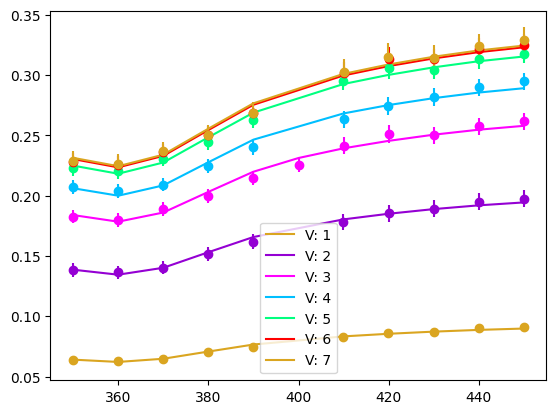

In [17]:
dictA_toPlot = {**resDict_A_UVall, **fixedPars_global_A}
for dc in data_UVall_A:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    # localPE = dc.resultDict["pe"]
    # print(dc.resultDict)
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.resultDict,  **dictA_toPlot)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o")
    
plt.legend()
plt.show()


In [18]:
peHarry = np.array([harryPedict[V] for V in voltageTracker])
ype = [peVals_A_dict[V] for V in voltageTracker]
ypeErrs = [peErrs_A_dict[V] for V in voltageTracker]

print("pe offset:", peVals_A - peHarry)
print("pe ratio:", 1-peHarry/peVals_A)

# plt.errorbar(voltageTracker, ype, yerr=ypeErrs, marker="o", label="Pe A fit")
# plt.plot(voltageTracker, peHarry, marker="o", label="Pe Harry")


# plt.plot(voltageTracker, peVals_A/peHarry, marker="o", label="ratio (this/harry)")
# plt.plot(voltageTracker, peHarry-peVals_A, marker="o", label="pe offset")

# plt.legend()

pe offset: [-0.225206 -0.168773 -0.109169 -0.085484 -0.045445 -0.043096 -0.050365]
pe ratio: [-0.86252777 -0.29876615 -0.14567521 -0.10176667 -0.04959079 -0.04591519
 -0.05342633]


---
---
### Fitting Entire Range - Vis
## Standard Vis fit - Permutation __S__

Front of junction is fixed
* fixed (nested/global): $P_e$, $d_p^*$ = values from fit A
* float nested: $P_h$
* float global: $X_{PN}$, $dw^*$

In [19]:
# fixedPars_Boring["smoothSigma"] = None

In [20]:
##-- Buiding Vis all dataset --##
v_0A = data_voltages[-1]
angle_0A = data_angles[0]
print(data_voltages[1:])

data_Vis_allS = []
onlyData_vis_all = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    fixedNuisDict = {"pe":peVals_A_dict[V]}
    floatNuisDict = {"ph": 0.15}
    floatBoundsNuisDict = {"ph": (0.0, 1.1)}
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict,
                                    nuisanceFixed=fixedNuisDict)
    odFullA.extraV = V
    data_Vis_allS.append(odFullA)
    onlyData_vis_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(onlyData_vis_all, True);
type(data_Vis_allS[0].oneDData);

[1 2 3 4 5 6 7 8]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


In [21]:
print("List of args needed:", SS.GetNames(PDE_allArgs))
print("using results from UV_A", resDict_A_UVall)

fixedPars_Vis_S = {"tOxide":ttGood, **resDict_A_UVall, **fixedPars_Boring}
print("\nfixed inputs:", fixedPars_Vis_S)

floatPars_Vis_S = {"Xpn": 0.6e3, "dw_star": 5e3}
floatParBounds_Vis_S = {"Xpn": (0.2e3, 8e3), "dw_star": (3e3, 20e3)}

x0_global_S, x0_global_S_Names = SS.BuildX0(floatDict=floatPars_Vis_S, functionToFit=PDE_allArgs)
x0_global_S_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Vis_S, functionToFit=PDE_allArgs)

print("------ Case S - Vis all ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_S, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
using results from UV_A {'dp_star': 1.1625}

fixed inputs: {'tOxide': 16.5, 'dp_star': 1.1625, 'FF': 0.6, 'quantum': False, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x11d679950>}
------ Case S - Vis all ------


1100.7417560652611

In [22]:
startTime = time.time()
globalFit_Visall_S = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_S, bounds = x0_global_S_bounds,
                                        args=(fixedPars_Vis_S, data_Vis_allS, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_Visall_S.x, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                                    functionToFit=PDE_allArgs, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", endTime-startTime)

Done fit! Time taken: 38.00754404067993


In [23]:
# print(globalFit_Visall_S)
print("score:", globalFit_Visall_S.fun)
resDict_VisAll_S = SS.GetResDict(globalFit_Visall_S, x0_global_S_Names)
resDictError_Visall_S = SS.GetResErrorDict(globalFit_Visall_S, x0_global_S_Names)
print("from UV fit:", resDict_A_UVall)
print("error UV fit:", resErrors_A_UVall)
print(resDict_VisAll_S)
print(resDictError_Visall_S)

phFull_dict_S = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_Vis_allS}
peFull_dict_A = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_UVall_A}

print("pe:", peFull_dict_A)
print("ph:", phFull_dict_S)


score: 271.2011357323522
from UV fit: {'dp_star': 1.1625}
error UV fit: {'dp_star': 0.0674}
{'Xpn': 1277.1266, 'dw_star': 6543.1734}
{'Xpn': 20.0981, 'dw_star': 133.1054}
pe: {1: (0.2611, 0.0017), 2: (0.5649, 0.0048), 3: (0.7494, 0.0046), 4: (0.84, 0.0049), 5: (0.9164, 0.0054), 6: (0.9386, 0.0062), 7: (0.9427, 0.0071)}
ph: {1: (0.0525, 0.0007), 2: (0.153, 0.0022), 3: (0.2502, 0.0023), 4: (0.3292, 0.0026), 5: (0.3789, 0.0029), 6: (0.4305, 0.0035), 7: (0.4821, 0.0042)}


{'dp_star': 1.1625, 'Xpn': 1277.1266, 'dw_star': 6543.1734, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x11d679950>}


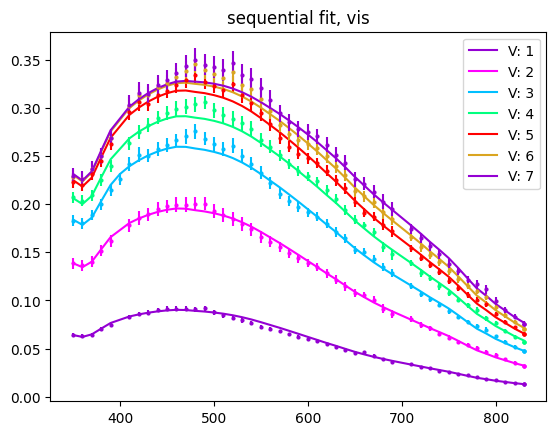

In [24]:
dict_visAll_S_final = {**resDict_A_UVall, **resDict_VisAll_S, **fixedPars_Vis_S}
print(dict_visAll_S_final)

otherDict = dict_visAll_S_final.copy()
otherDict["dh"] = dhStandard

for dc in data_Vis_allS:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPe = peFull_dict_A[voltage][0]
    localPh = phFull_dict_S[voltage][0]
    pArgs = {"pe": localPe, **dc.resultDict}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_visAll_S_final, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    # yFit_standard = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **otherDict, **pArgs)
    # plt.plot(xwlen, yFit_standard, color = col, linestyle="--")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

plt.title("sequential fit, vis")
plt.legend()
plt.show()

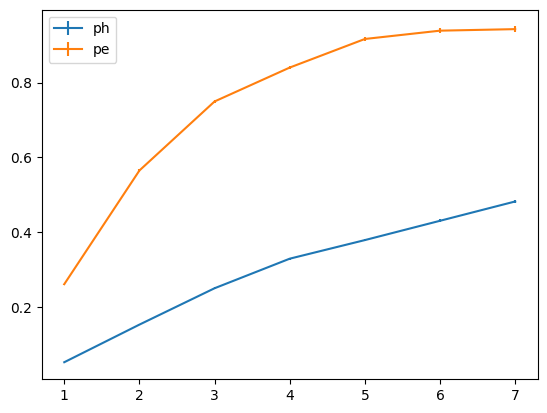

In [25]:
yph_visS = [phFull_dict_S[voltage][0] for voltage in voltageTracker]
yphErr_visS = [phFull_dict_S[voltage][1] for voltage in voltageTracker]

ype_UV = [peFull_dict_A[voltage][0] for voltage in voltageTracker]
ypeErr_UV = [peFull_dict_A[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph_visS, yphErr_visS, label="ph")
plt.errorbar(voltageTracker, ype_UV, ypeErr_UV, label="pe")

plt.legend()

---
---
## Global fit
Relative to __S__ above, this also float $dp^*$ and floats both $P$ values for each voltage
* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_e$, $P_h$

In [26]:
# fixedPars_Boring["smoothSigma"] = 7

In [27]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_global1 = []
visCut = 900
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < visCut)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fullFloat = {"pe": peVals_A_dict[V], "ph": 0.4}
    fullBounds = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global1.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [28]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global1 = {"tOxide":ttGood, **fixedPars_Boring}
print("\nfixed inputs:", fixedPars_global1)

floatPars_global1 = {"dp_star":resDict_A_UVall["dp_star"], "Xpn": 1.5e3, "dw_star": 8e3}
floatParBounds_global1 = {"dp_star":(0.5, 15), "Xpn": (0.2e3, 8e3), "dw_star": (2e3, 20e3)}

x0_global1, x0_global1_Names = SS.BuildX0(floatDict=floatPars_global1, functionToFit=PDE_allArgs)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=PDE_allArgs)

print("------ Case global1 setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global1, globalFixed=fixedPars_global1, dataPackage=data_global1,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']

fixed inputs: {'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x11d679950>}
------ Case global1 setup ------


264.9414387240284

In [29]:
starTime = time.time()
globalFit_global1 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global1, bounds = x0_global1_bounds,
                                        args=(fixedPars_global1, data_global1, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global1.x, globalFixed=fixedPars_global1, dataPackage=data_global1,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!, time taken:", time.time()-starTime)

Done fit!, time taken: 68.13879704475403


In [30]:
# print(globalFit_Visall_S)
print("score:", globalFit_global1.fun)
resDict_global1 = SS.GetResDict(globalFit_global1, x0_global1_Names)
resDictError_global1 = SS.GetResErrorDict(globalFit_global1, x0_global1_Names)
print(resDict_global1)
print(resDictError_global1)

phFull_dict_global1 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global1}
peFull_dict_global1 = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global1}

print("pe:", peFull_dict_global1)
print("ph:", phFull_dict_global1)

score: 219.12553735557395
{'dp_star': 1.3966, 'Xpn': 1239.1483, 'dw_star': 6751.4103}
{'dp_star': 0.0531, 'Xpn': 21.671, 'dw_star': 110.0249}
pe: {1: (0.2594, 0.0011), 2: (0.5693, 0.0033), 3: (0.7631, 0.0032), 4: (0.8626, 0.0034), 5: (0.9349, 0.0038), 6: (0.9624, 0.0044), 7: (0.9744, 0.0051)}
ph: {1: (0.0544, 0.0008), 2: (0.1521, 0.0026), 3: (0.2437, 0.0027), 4: (0.3168, 0.003), 5: (0.3676, 0.0033), 6: (0.4151, 0.004), 7: (0.4611, 0.0047)}


{'dp_star': 1.3966, 'Xpn': 1239.1483, 'dw_star': 6751.4103, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x11d679950>}


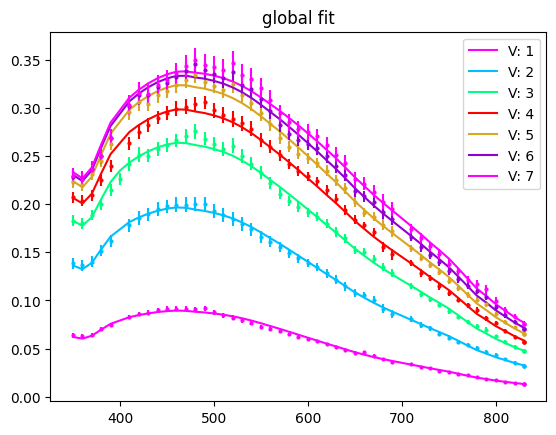

In [31]:
dict_final_global1 = {**resDict_global1, **fixedPars_global1}
print(dict_final_global1)

for dc in data_global1:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPe = peFull_dict_global1[voltage][0]
    localPh = phFull_dict_global1[voltage][0]
    pArgs = {"pe": localPe, "ph": localPh}
    pArgs = dc.resultDict
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global1, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

plt.title("global fit")
plt.legend()
plt.show()

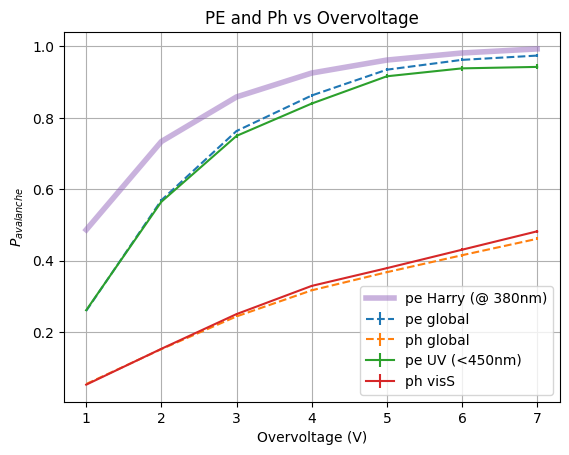

In [32]:
ms.ResetColorCycle()

yph_global = [phFull_dict_global1[voltage][0] for voltage in voltageTracker]
yphErr_global = [phFull_dict_global1[voltage][1] for voltage in voltageTracker]

ype_global = [peFull_dict_global1[voltage][0] for voltage in voltageTracker]
ypeErr_global = [peFull_dict_global1[voltage][1] for voltage in voltageTracker]

yPeHarry = [harryPedict[V] for V in voltageTracker]

plt.errorbar(voltageTracker, ype_global, ypeErr_global, linestyle = "--", label="pe global")
plt.errorbar(voltageTracker, yph_global, yphErr_global, linestyle = "--", label="ph global")

plt.errorbar(voltageTracker, ype_UV, ypeErr_UV, label=f"pe UV (<{UVLim:d}nm)")
plt.errorbar(voltageTracker, yph_visS, yphErr_visS, label="ph visS")

plt.plot(voltageTracker, yPeHarry, linewidth = 4, alpha=0.5, label="pe Harry (@ 380nm)")

plt.title("PE and Ph vs Overvoltage")
plt.xlabel("Overvoltage (V)")
plt.ylabel(r"$P_{avalanche}$")

plt.legend()
plt.grid()
plt.show()

{'dp_star': 1.3966, 'Xpn': 1239.1483, 'dw_star': 6751.4103}
{'dp_star': 0.0531, 'Xpn': 21.671, 'dw_star': 110.0249}
{'dp_star': 1.1625}
{'Xpn': 1277.1266, 'dw_star': 6543.1734}


[]

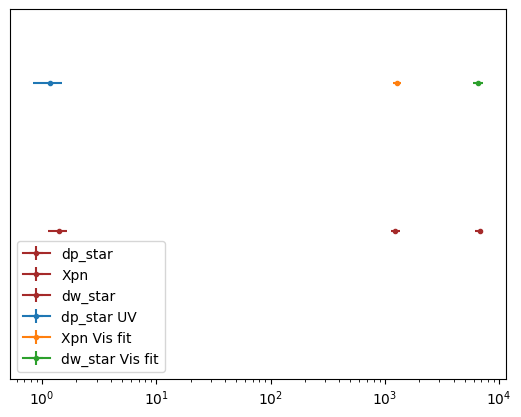

In [33]:
## printing results
print(resDict_global1)
print(resDictError_global1)

print(resDict_A_UVall)
print(resDict_VisAll_S)

scaleXError = 5

plt.errorbar(x = resDict_global1["dp_star"], y = 0, yerr=0, xerr= scaleXError * resDictError_global1["dp_star"], marker=".", color='brown', label="dp_star")
plt.errorbar(x = resDict_global1["Xpn"], y = 0, yerr=0, xerr= scaleXError * resDictError_global1["Xpn"], marker=".", color='brown', label="Xpn")
plt.errorbar(x = resDict_global1["dw_star"], y = 0, yerr=0, xerr= scaleXError * resDictError_global1["dw_star"], marker=".", color='brown', label="dw_star")

plt.errorbar(x = resDict_A_UVall["dp_star"], y = 0.01, yerr=0, xerr= scaleXError * resErrors_A_UVall["dp_star"], marker=".", label="dp_star UV")
plt.errorbar(x=resDict_VisAll_S["Xpn"], y=0.01, yerr=0, xerr= scaleXError * resDictError_Visall_S["Xpn"], marker=".", label="Xpn Vis fit")
plt.errorbar(x=resDict_VisAll_S["dw_star"], y=0.01, yerr=0, xerr= scaleXError * resDictError_Visall_S["dw_star"], marker=".", label="dw_star Vis fit")

plt.legend()

plt.ylim(-0.01, 0.015)
plt.yticks([])
plt.xscale("log")
plt.plot()